## Dizüstü bilgisayar fiyat tahmini projesi
Projenin amacı: Bilgisayarın teknik özelliklerinden hareketle fiyatını tahmin eden bir regresyon modeli oluşturmak.

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("laptop_data.csv")

df.head()

,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


In [2]:
df.shape

(1303, 12)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1303 non-null   int64  
 1   Company           1303 non-null   str    
 2   TypeName          1303 non-null   str    
 3   Inches            1303 non-null   float64
 4   ScreenResolution  1303 non-null   str    
 5   Cpu               1303 non-null   str    
 6   Ram               1303 non-null   str    
 7   Memory            1303 non-null   str    
 8   Gpu               1303 non-null   str    
 9   OpSys             1303 non-null   str    
 10  Weight            1303 non-null   str    
 11  Price             1303 non-null   float64
dtypes: float64(2), int64(1), str(9)
memory usage: 261.0 KB


In [4]:
df.describe()

,Unnamed: 0,Inches,Price
count,1303.00000,1303.000000,1303.000000
mean,651.00000,15.017191,59870.042910
std,376.28801,1.426304,37243.201786
min,0.00000,10.100000,9270.720000
25%,325.50000,14.000000,31914.720000
50%,651.00000,15.600000,52054.560000
75%,976.50000,15.600000,79274.246400
max,1302.00000,18.400000,324954.720000


In [5]:
df.columns

Index(['Unnamed: 0', 'Company', 'TypeName', 'Inches', 'ScreenResolution',
       'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight', 'Price'],
      dtype='str')

In [6]:
# Gereksiz sütunu kaldıralım

df = df.drop("Unnamed: 0", axis=1)


In [7]:
df.columns

Index(['Company', 'TypeName', 'Inches', 'ScreenResolution', 'Cpu', 'Ram',
       'Memory', 'Gpu', 'OpSys', 'Weight', 'Price'],
      dtype='str')

In [8]:
df.isna().sum()

Company             0
TypeName            0
Inches              0
ScreenResolution    0
Cpu                 0
Ram                 0
Memory              0
Gpu                 0
OpSys               0
Weight              0
Price               0
dtype: int64

In [9]:
# RAM sütunundaki GB ifadesini kaldıralım
df["Ram"] = df["Ram"].str.replace("GB", "", regex=False)


In [10]:
# Weight sütunundaki kg ifadesini kaldıralım
df["Weight"] = df["Weight"].str.replace("kg", "", regex=False)

In [11]:
# Sütunları sayısal veri tipine dönüştürelim
df["Ram"] = pd.to_numeric(df["Ram"])
df["Weight"] = pd.to_numeric(df["Weight"])

In [12]:
# Sonuçları kontrol edelim
df[["Ram", "Weight"]].head()


,Ram,Weight
0,8,1.37
1,8,1.34
2,8,1.86
3,16,1.83
4,8,1.37


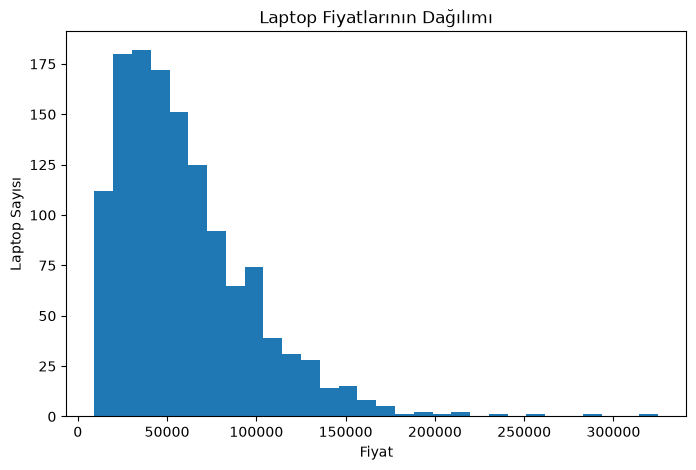

In [13]:
import matplotlib.pyplot as plt

# Laptop fiyatlarının dağılımı
plt.figure(figsize=(8, 5))
plt.hist(df["Price"], bins=30)
plt.title("Laptop Fiyatlarının Dağılımı")
plt.xlabel("Fiyat")
plt.ylabel("Laptop Sayısı")
plt.show()


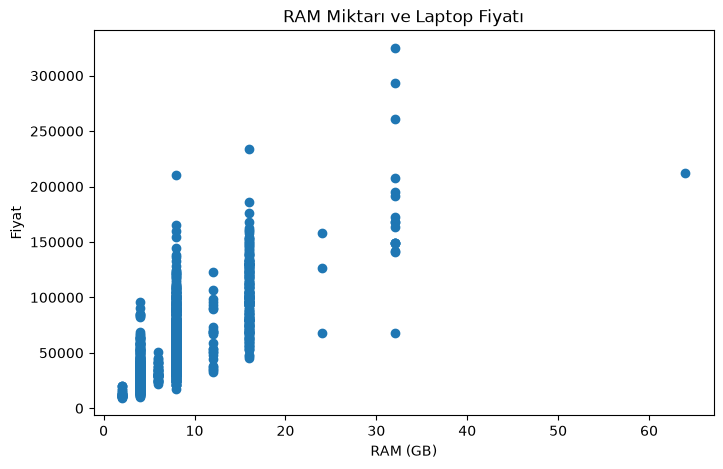

In [14]:
# RAM miktarı ile fiyat ilişkisi
plt.figure(figsize=(8, 5))
plt.scatter(df["Ram"], df["Price"])
plt.title("RAM Miktarı ve Laptop Fiyatı")
plt.xlabel("RAM (GB)")
plt.ylabel("Fiyat")
plt.show()


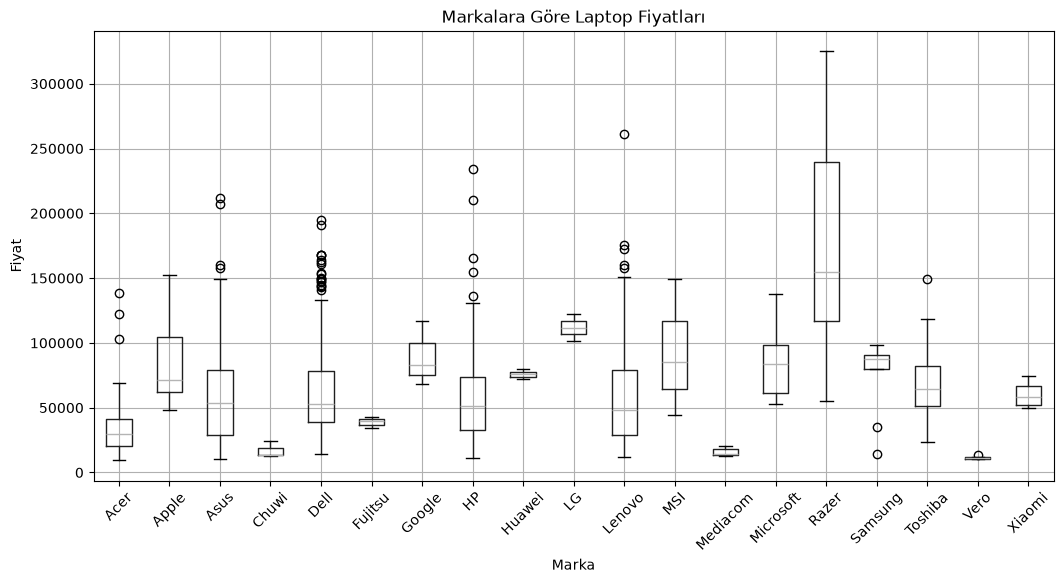

In [15]:

# Orijinal veriyi yeniden yükleyelim
df_eda = pd.read_csv("laptop_data.csv")

# Markalara göre laptop fiyatları
df_eda.boxplot(column="Price", by="Company", figsize=(12, 6))
plt.title("Markalara Göre Laptop Fiyatları")
plt.suptitle("")
plt.xlabel("Marka")
plt.ylabel("Fiyat")
plt.xticks(rotation=45)
plt.show()

In [16]:
#Feature Engineerinng

In [17]:
# Ekran çözünürlüğü sütunundaki örnek değerler
df["ScreenResolution"].head()


0    IPS Panel Retina Display 2560x1600
1                              1440x900
2                     Full HD 1920x1080
3    IPS Panel Retina Display 2880x1800
4    IPS Panel Retina Display 2560x1600
Name: ScreenResolution, dtype: str

In [18]:
 # Ekran çözünürlüğünden yatay ve dikey değerleri ayıralım
df["Resolution"] = df["ScreenResolution"].str.extract(r"(\d+x\d+)")

df[["ScreenResolution", "Resolution"]].head()


,ScreenResolution,Resolution
0,IPS Panel Retina Display 2560x1600,2560x1600
1,1440x900,1440x900
2,Full HD 1920x1080,1920x1080
3,IPS Panel Retina Display 2880x1800,2880x1800
4,IPS Panel Retina Display 2560x1600,2560x1600


In [19]:

# Yatay ve dikey çözünürlük değerlerini ayıralım
df[["X_res", "Y_res"]] = df["Resolution"].str.split("x", expand=True)

# Yeni sütunları sayısal değerlere dönüştürelim
df["X_res"] = pd.to_numeric(df["X_res"])
df["Y_res"] = pd.to_numeric(df["Y_res"])

# Sonucu kontrol edelim
df[["Resolution", "X_res", "Y_res"]].head()


,Resolution,X_res,Y_res
0,2560x1600,2560,1600
1,1440x900,1440,900
2,1920x1080,1920,1080
3,2880x1800,2880,1800
4,2560x1600,2560,1600


In [20]:

# Gereksiz ara sütunu kaldıralım
df = df.drop("Resolution", axis=1)

# Kategorik sütunları sayısal değerlere dönüştürelim
df = pd.get_dummies(df, drop_first=True)

# İlk satırları kontrol edelim
df.head()

,Inches,Ram,Weight,Price,X_res,Y_res,Company_Apple,Company_Asus,Company_Chuwi,Company_Dell,...,Gpu_Nvidia Quadro M620,Gpu_Nvidia Quadro M620M,OpSys_Chrome OS,OpSys_Linux,OpSys_Mac OS X,OpSys_No OS,OpSys_Windows 10,OpSys_Windows 10 S,OpSys_Windows 7,OpSys_macOS
0,13.3,8,1.37,71378.6832,2560,1600,True,False,False,False,...,False,False,False,False,False,False,False,False,False,True
1,13.3,8,1.34,47895.5232,1440,900,True,False,False,False,...,False,False,False,False,False,False,False,False,False,True
2,15.6,8,1.86,30636.0000,1920,1080,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False
3,15.4,16,1.83,135195.3360,2880,1800,True,False,False,False,...,False,False,False,False,False,False,False,False,False,True
4,13.3,8,1.37,96095.8080,2560,1600,True,False,False,False,...,False,False,False,False,False,False,False,False,False,True


In [21]:
# Bağımsız değişkenler
X = df.drop("Price", axis=1)

# Bağımlı değişken
y = df["Price"]

# Boyutları kontrol edelim
X.shape, y.shape


((1303, 339), (1303,))

In [22]:

from sklearn.model_selection import train_test_split

# Veriyi eğitim ve test olarak ayıralım
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Veri boyutlarını kontrol edelim
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((1042, 339), (261, 339), (1042,), (261,))

In [23]:
# 1.Model Linear Regression Modeli eğitme ve tahmin yapma

In [24]:

from sklearn.linear_model import LinearRegression

# Modeli oluşturalım
model = LinearRegression()

# Modeli eğitim verileriyle eğitelim
model.fit(X_train, y_train)

# Test verileri üzerinde tahmin yapalım
y_pred = model.predict(X_test)

# İlk tahminleri görüntüleyelim
y_test.head(), y_pred[:5]

(479     89084.16
 1022    61218.72
 298     26586.72
 1265    47898.72
 774     66280.32
 Name: Price, dtype: float64,
 array([67054.80758719, 60716.57646733, 31085.76357584, 54466.82618881,
        63056.22548566]))

In [25]:
# Model başarısını ölçme

In [26]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Modelin başarı değerlerini hesaplayalım
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

# Sonuçları görüntüleyelim
r2, mae, mse

(0.8436835032019199,
 np.float64(10320.999914769729),
 np.float64(225389738.06868115))

Sonuçları nasıl yorumlayacağız?
- R² = 0,8437: Modelin fiyatları açıklama gücü oldukça iyi görünüyor.
- MAE = 10.321: Tahminler, gerçek fiyatlardan ortalama yaklaşık 10.321 fiyat birimi kadar sapıyor.
- MSE = 225.389.738,07: Büyük tahmin hatalarını daha fazla ağırlıklandıran hata ölçüsüdür. Tek başına yorumlamaktansa MAE ve R² ile birlikte değerlendirilmelidir.
Ödevin kısa değerlendirmesi
Laptop fiyatları; marka, RAM, işlemci, ekran çözünürlüğü ve diğer teknik özelliklerle tahmin edildi. Veri seti temizlendi, gerekli sütunlar sayısal forma dönüştürüldü, eğitim ve test verileri ayrıldı ve LinearRegression modeli eğitildi.
Önemli: Hocanın standart kodlarından sapmadan elde ettiğimiz mevcut sonuçlar bunlar. Şimdilik modeli iyileştirmek için ek yöntemler uygulamıyoruz. Ödevin tesliminde bu sonuçları ve kısa değerlendirmeyi kullanabilirsin.

## 2. Model: Decision Tree Regressor

In [27]:
from sklearn.tree import DecisionTreeRegressor

# Modeli oluşturalım
model_dt = DecisionTreeRegressor(random_state=42)

# Modeli eğitelim
model_dt.fit(X_train, y_train)

# Tahmin yapalım
y_pred_dt = model_dt.predict(X_test)

# Model sonuçlarını hesaplayalım
r2_dt = r2_score(y_test, y_pred_dt)
mae_dt = mean_absolute_error(y_test, y_pred_dt)
mse_dt = mean_squared_error(y_test, y_pred_dt)

r2_dt, mae_dt, mse_dt

(0.7037891908883172,
 np.float64(12771.390537931034),
 np.float64(427100645.4618441))

## 3. Model: Random Forest Regressor

In [28]:
from sklearn.ensemble import RandomForestRegressor

# Modeli oluşturalım
model_rf = RandomForestRegressor(n_estimators=100, random_state=42)

# Modeli eğitelim
model_rf.fit(X_train, y_train)

# Tahmin yapalım
y_pred_rf = model_rf.predict(X_test)

# Model sonuçlarını hesaplayalım
r2_rf = r2_score(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)

r2_rf, mae_rf, mse_rf

(0.7924357963963942,
 np.float64(10471.264035985552),
 np.float64(299282816.85510314))

## Üç Modelin Karşılaştırılması

In [29]:
sonuclar = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree", "Random Forest"],
    "R2": [r2, r2_dt, r2_rf],
    "MAE": [mae, mae_dt, mae_rf],
    "MSE": [mse, mse_dt, mse_rf]
})

sonuclar.sort_values("R2", ascending=False)

,Model,R2,MAE,MSE
0,Linear Regression,0.843684,10320.999915,2.253897e+08
2,Random Forest,0.792436,10471.264036,2.992828e+08
1,Decision Tree,0.703789,12771.390538,4.271006e+08


## Genel Değerlendirme
Bu çalışmada laptop fiyatını tahmin etmek için üç farklı regresyon modeli kullanılmıştır: Linear Regression, Decision Tree Regressor ve Random Forest Regressor. Modeller aynı eğitim-test ayrımıyla değerlendirilmiştir. Karşılaştırma tablosundaki R², MAE ve MSE değerlerine göre sonuçlar yorumlanmalıdır. En yüksek R² değerine sahip model her zaman tek başına yeterli olmayabileceğinden MAE ve MSE değerleri de birlikte incelenmelidir.